In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target

print(df.shape)
df.head()


(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

X = df.drop('target', axis=1)
y = df['target']
X_scaled = StandardScaler().fit_transform(X)

km1 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels1 = km1.fit_predict(X)

km2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels2 = km2.fit_predict(X_scaled)

results = pd.DataFrame({
        "Data": ["Without scaling", "With scaling"],
        "Silhouette": [round(silhouette_score(X, labels1),3), round(silhouette_score(X_scaled, labels2),3)],
         "ARI": [round(adjusted_rand_score(y, labels1), 3), round(adjusted_rand_score(y, labels2), 3 )]
    })

results

,Data,Silhouette,ARI
0,Without scaling,0.697,0.491
1,With scaling,0.343,0.654


In [4]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

selector = SelectKBest(score_func=f_classif, k=10)
X_selected = selector.fit_transform(X_scaled, y)
print("Selected:", list(X.columns[selector.get_support()]))

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)
print("PCA components:", X_pca.shape[1])
print("Variance kept:", round(pca.explained_variance_ratio_.sum(), 3))

km_a = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_a = km_a.fit_predict(X_selected)
km_b = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_b = km_b.fit_predict(X_pca)

pd.DataFrame({
    "Data": ["All 30 (scaled)", "Top 10 selected", "PCA 95%"],
    "Silhouette": [round(silhouette_score(X_scaled, labels2), 3),
                round(silhouette_score(X_selected, labels_a), 3),
                round(silhouette_score(X_scaled, labels_b), 3),],
    "ARI": [round(adjusted_rand_score(y, labels2),3),
    round(adjusted_rand_score(y, labels_a),3),
    round(adjusted_rand_score(y, labels_b),3),]
})


Selected: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
PCA components: 10
Variance kept: 0.952


,Data,Silhouette,ARI
0,All 30 (scaled),0.343,0.654
1,Top 10 selected,0.563,0.687
2,PCA 95%,0.345,0.671


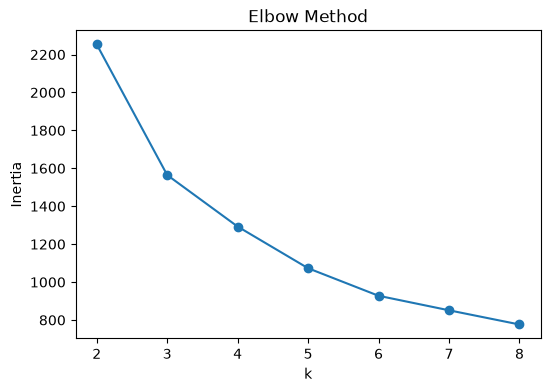

In [5]:
ks = list(range(2, 9))
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_selected).inertia_ for k in ks]

plt.figure(figsize=(6, 4))
plt.plot(ks, inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.show()

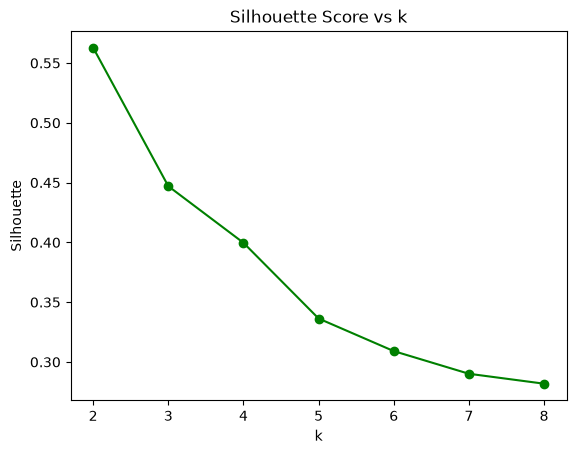

{2: 0.563, 3: 0.447, 4: 0.4, 5: 0.336, 6: 0.309, 7: 0.29, 8: 0.282}


In [6]:
sils = [silhouette_score(X_selected, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_selected)) for k in ks]
plt.plot(ks, sils, marker='o', color='green')
plt.title('Silhouette Score vs k')
plt.xlabel('k')
plt.ylabel('Silhouette')
plt.show()

print(dict(zip(ks, [round(s, 3) for s in sils])))

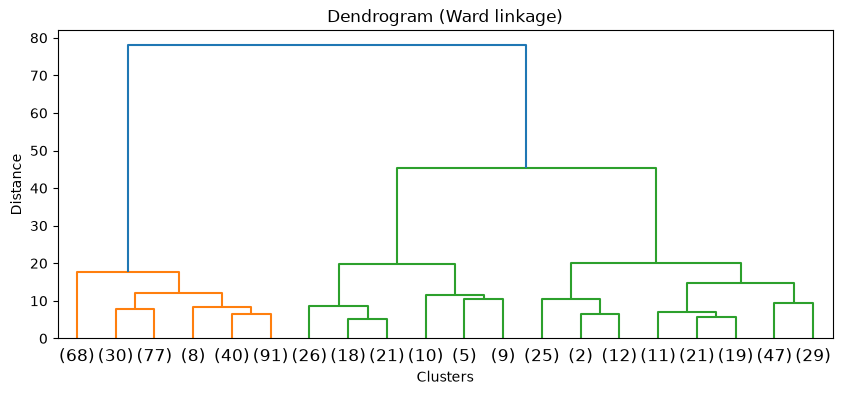

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram
Z = linkage(X_selected, method='ward')

plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode='lastp', p=20)
plt.title('Dendrogram (Ward linkage)')
plt.xlabel("Clusters")
plt.ylabel('Distance')
plt.show()

In [8]:
from sklearn.cluster import KMeans,AgglomerativeClustering
hc =  AgglomerativeClustering(n_clusters=2, linkage='ward')
hc.fit(X_selected)
labels_h = hc.labels_

print("Hierarchical -> Silhouette:", round(silhouette_score(X_selected, labels_h), 3),
      "ARI:", round(adjusted_rand_score(y, labels_h), 3))
print("K-Means -> Silhouette:", round(silhouette_score(X_selected, labels_a), 3),
      "ARI:", round(adjusted_rand_score(y, labels_a), 3))


Hierarchical -> Silhouette: 0.472 ARI: 0.65
K-Means -> Silhouette: 0.563 ARI: 0.687


In [9]:
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
rf = RandomForestClassifier(random_state=42)

cv_lr = cross_val_score(lr, X, y, cv=5)
cv_rf = cross_val_score(rf, X, y, cv=5)

print("Logistic Regression folds:",np.round(cv_lr, 3))
print("Logistic Regression mean:", round(cv_lr.mean(), 3))
print("Random Forest folds:", np.round(cv_rf, 3))
print("Random Forest mean:", round(cv_rf.mean(), 3))


Logistic Regression folds: [0.982 0.982 0.974 0.974 0.991]
Logistic Regression mean: 0.981
Random Forest folds: [0.921 0.939 0.982 0.965 0.973]
Random Forest mean: 0.956


[[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

ROC-AUC: 0.995


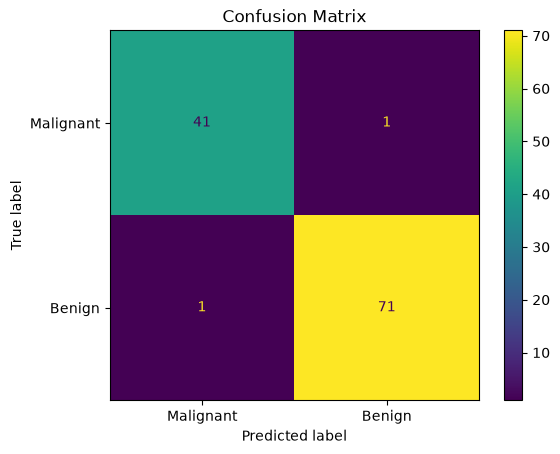

In [10]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, ConfusionMatrixDisplay
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Malignant', 'Benign'])
plt.title('Confusion Matrix')
plt.show()

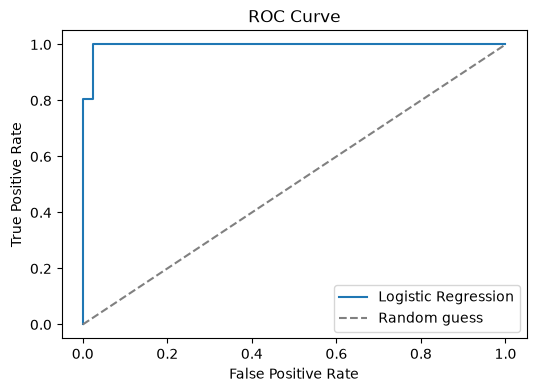

In [11]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.title("ROC Curve")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, recall_score

rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train, y_train)
rf_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42), rf_grid, cv=5, scoring='accuracy', n_jobs=-1)
gs_rf.fit(X_train, y_train)

print("Best RF settings:", gs_rf.best_params_)
print("Best RF CV accuracy:", round(gs_rf.best_score_, 3))

Best RF settings: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best RF CV accuracy: 0.96


In [13]:
lr_base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr_base.fit(X_train, y_train)

lr_grid = {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}
gs_lr = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), lr_grid, cv=5, scoring='accuracy')
gs_lr.fit(X_train, y_train)

print("Best LR settings:", gs_lr.best_params_)
print("Best LR CV accuracy:", round(gs_lr.best_score_,3))


Best LR settings: {'logisticregression__C': 0.1}
Best LR CV accuracy: 0.98


In [14]:
names = ["Logistic Regression (before)", "Logistic Regression (tuned)", "Random Forest (before)", "Random Forest (tuned)"]
mods = [lr_base, gs_lr.best_estimator_, rf_base, gs_rf.best_estimator_]

table = pd.DataFrame({
    "Model": names,
    "Accuracy": [round(accuracy_score(y_test, m.predict(X_test)), 3) for m in mods],
    "Malignant recall": [round(recall_score(y_test, m.predict(X_test), pos_label=0), 3) for m in mods],
    "F1 (macro)": [round(f1_score(y_test, m.predict(X_test), average='macro'), 3) for m in mods],
    "ROC-AUC": [round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 3) for m in mods]
})
table

,Model,Accuracy,Malignant recall,F1 (macro),ROC-AUC
0,Logistic Regression (before),0.982,0.976,0.981,0.995
1,Logistic Regression (tuned),0.974,0.952,0.972,0.996
2,Random Forest (before),0.956,0.929,0.953,0.994
3,Random Forest (tuned),0.956,0.929,0.953,0.993


                          Method  Silhouette    ARI
0            K-Means, no scaling       0.697  0.491
1   K-Means, scaled(30 features)       0.343  0.654
2       K-Means, top 10 features       0.583  0.687
3     K-Means, PCA 95%(10 comp.)       0.345  0.671
4  Hierarchical, top 10 features       0.472  0.650


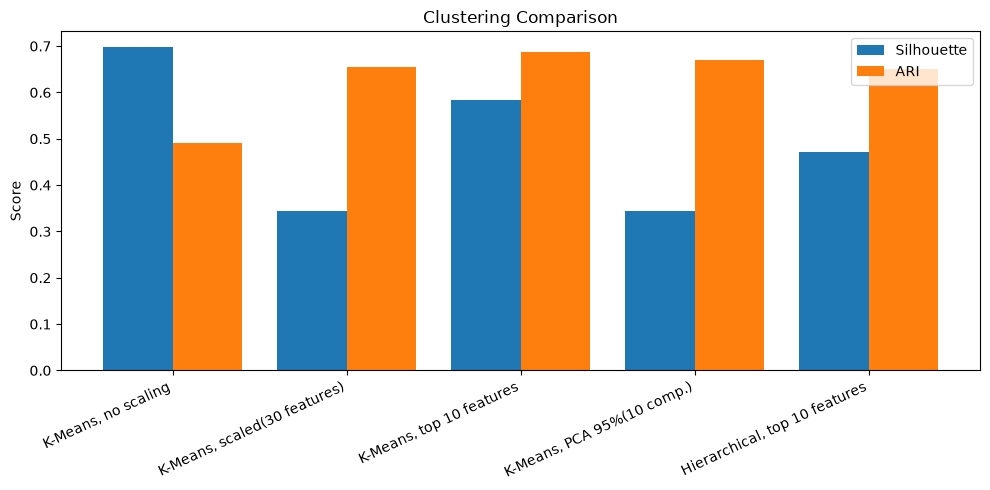

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cluster_table = pd.DataFrame({
    "Method": ["K-Means, no scaling", "K-Means, scaled(30 features)", "K-Means, top 10 features", "K-Means, PCA 95%(10 comp.)", "Hierarchical, top 10 features"],
    "Silhouette": [0.697, 0.343, 0.583, 0.345, 0.472],
    "ARI": [0.491, 0.654, 0.687, 0.671, 0.650]
})
print(cluster_table)

pos = np.arange(len(cluster_table))
plt.figure(figsize=(10, 5))
plt.bar(pos - 0.2, cluster_table["Silhouette"], width=0.4, label="Silhouette")
plt.bar(pos + 0.2, cluster_table["ARI"], width=0.4, label="ARI")
plt.xticks(pos, cluster_table["Method"], rotation=25, ha="right")
plt.ylabel("Score")
plt.title("Clustering Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("Clustering_comparison.png", dpi=150)
plt.show()

                          Model  Accuracy  Malignant recall  F1 (macro)  \
0  Logistic Regression (before)     0.982             0.976       0.981   
1   Logistic Regression (tuned)     0.974             0.952       0.972   
2        Random Forest (before)     0.956             0.929       0.953   
3         Random Forest (tuned)     0.956             0.929       0.953   

   ROC-AUC  
0    0.995  
1    0.996  
2    0.994  
3    0.993  


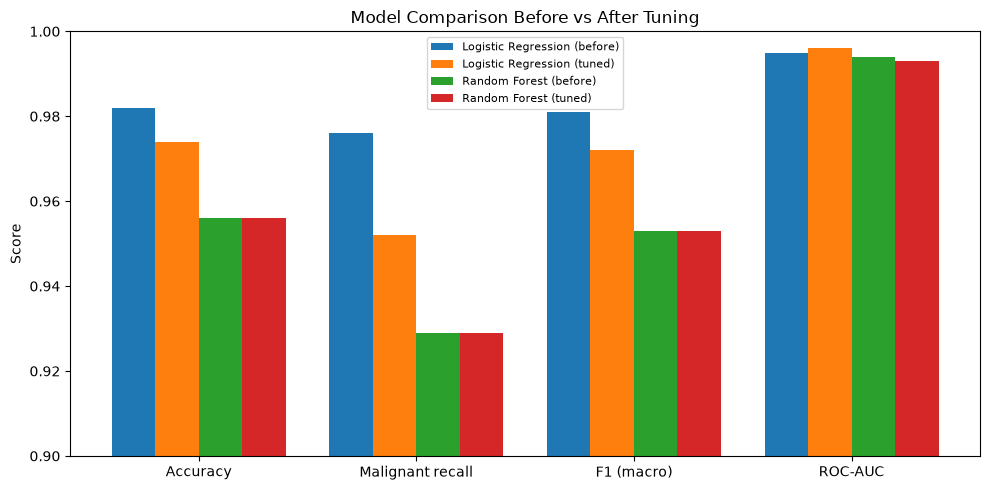

In [16]:
model_table = pd.DataFrame({
    "Model": ["Logistic Regression (before)", "Logistic Regression (tuned)", "Random Forest (before)", "Random Forest (tuned)"],
    "Accuracy": [0.982, 0.974, 0.956, 0.956],
    "Malignant recall": [0.976, 0.952, 0.929, 0.929],
    "F1 (macro)": [0.981, 0.972, 0.953, 0.953],
    "ROC-AUC": [0.995, 0.996, 0.994, 0.993]
})
print(model_table)

metrics = ["Accuracy", "Malignant recall", "F1 (macro)", "ROC-AUC"]
pos = np.arange(len(metrics))
plt.figure(figsize=(10, 5))
for i in range(len(model_table)):
    plt.bar(pos + i * 0.2 - 0.3, model_table.loc[i, metrics].values.astype(float),width=0.2, label=model_table.loc[i, "Model"])
plt.xticks(pos, metrics)
plt.ylim(0.9, 1.0)
plt.ylabel("Score")
plt.title("Model Comparison Before vs After Tuning")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

In [17]:
print("Selected features:", list(X.columns[selector.get_support()]))
print("Silhouette by k:", dict(zip(ks, [round(s, 3) for s in sils])))
print("Best RF settings:", gs_rf.best_params_)
print("Best LR settings:", gs_lr.best_params_)
print("Best LR CV accuracy:", round(gs_lr.best_score_, 3))

Selected features: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Silhouette by k: {2: 0.563, 3: 0.447, 4: 0.4, 5: 0.336, 6: 0.309, 7: 0.29, 8: 0.282}
Best RF settings: {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Best LR settings: {'logisticregression__C': 0.1}
Best LR CV accuracy: 0.98


## Conclusion

1. **Preprocessing matters:** Scaling raised the clustering ARI from 0.491 to 0.654,even though the silhouette score drpped, so a high silhouette alone can be misleading.
2. **Dimensionality reduction helps:** The top 10 selected features gave the best K-means result and PCA kept 95.2% of thevariance withjust 10 components.
3. **Best clustering:** K-Means with k=2 beat hierarchicalclustering, supported by the silhouette scores and gthe dendrogram.
4. **Best classifier:** Logistic Regression reached 0.981 cross-validated accuracy, 0.98 test accuracy and ROC-AUC 0.995, missing only 1 malignant caseout of 42.
5. **Tuning:** GridSearchCV gave no test-set gain because the default models were already strong, and with only 114 test samples one patient changes accuracy by about 0.9%.
